<a href="https://colab.research.google.com/github/Laura-RFLopes/python_sis_26_2/blob/laura_lopes/aula13/laura_lopes_aula_13_exercicio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:
#Atividade 1

# Importação das bibliotecas
import pandas as pd
import numpy as np
import kagglehub
import os

#https://www.kaggle.com/datasets/avi1023/color-names
# Acesso ao dataset do Kaggle
path = kagglehub.dataset_download(
    "avi1023/color-names"
)

# Listar os arquivos disponíveis
print("Arquivos encontrados:", os.listdir(path))



100%|██████████| 25.3k/25.3k [00:00<00:00, 28.1MB/s]

Extracting files...
Arquivos encontrados: ['color_names.csv']


In [19]:
# Caminho do arquivo CSV
arquivo_csv = os.path.join(path, "color_names.csv")

# Carregar a base de dados
df = pd.read_csv(arquivo_csv)

# Visualizar as primeiras linhas
print(df.head())

# Verificar informações da base
print(df.info())

# Verificar valores ausentes
print(df.isnull().sum())

# Verificar registros duplicados
print("Duplicados:", df.duplicated().sum())

             Name Hex (24 bit)  Red (8 bit)  Green (8 bit)  Blue (8 bit)  \
0   Absolute zero      #0048BA            0             72           186   
1      Acid green      #B0BF1A          176            191            26   
2            Aero      #7CB9E8          124            185           232   
3       Aero blue      #C9FFE5          201            255           229   
4  African violet      #B284BE          178            132           190   

   Hue (degrees)  HSL.S (%)  HSL.L (%), HSV.S (%), HSV.V (%)  
0          217.0      100.0                             37.0  
1           65.0       76.0                             43.0  
2          206.0       70.0                             70.0  
3          151.0      100.0                             89.0  
4          288.0       31.0                             63.0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1298 entries, 0 to 1297
Data columns (total 8 columns):
 #   Column                           Non-Null Count  Dtype

In [23]:

# Remover registros duplicados
df = df.drop_duplicates()

# Remover espaços extras nos nomes das colunas
df.columns = df.columns.str.strip()

# Remover espaços extras em colunas de texto
for coluna in df.select_dtypes(include="object").columns:
    df[coluna] = df[coluna].str.strip()

# Verificar valores ausentes
print("Valores ausentes:")
print(df.isnull().sum())

# Remover linhas com valores ausentes
df = df.dropna()

# Verificar novamente os valores ausentes
print("Valores ausentes após limpeza:")
print(df.isnull().sum())

# Verificar duplicados após limpeza
print("Duplicados após limpeza:", df.duplicated().sum())



Valores ausentes:
Name                               0
Hex (24 bit)                       0
Red (8 bit)                        0
Green (8 bit)                      0
Blue (8 bit)                       0
Hue (degrees)                      0
HSL.S (%)                          0
HSL.L (%), HSV.S (%), HSV.V (%)    0
dtype: int64
Valores ausentes após limpeza:
Name                               0
Hex (24 bit)                       0
Red (8 bit)                        0
Green (8 bit)                      0
Blue (8 bit)                       0
Hue (degrees)                      0
HSL.S (%)                          0
HSL.L (%), HSV.S (%), HSV.V (%)    0
dtype: int64
Duplicados após limpeza: 0


In [24]:
# Mostrar os nomes das colunas
print(df.columns.tolist())

# Mostrar uma amostra maior da base
print(df.head(10))

# Verificar os tipos de dados
print(df.dtypes)

['Name', 'Hex (24 bit)', 'Red (8 bit)', 'Green (8 bit)', 'Blue (8 bit)', 'Hue (degrees)', 'HSL.S (%)', 'HSL.L (%), HSV.S (%), HSV.V (%)']
                    Name Hex (24 bit)  Red (8 bit)  Green (8 bit)  \
0          Absolute zero      #0048BA            0             72   
1             Acid green      #B0BF1A          176            191   
2                   Aero      #7CB9E8          124            185   
3              Aero blue      #C9FFE5          201            255   
4         African violet      #B284BE          178            132   
5   Air Force blue (RAF)      #5D8AA8           93            138   
6  Air Force blue (USAF)      #00308F            0             48   
7   Air superiority blue      #72A0C1          114            160   
8        Alabama crimson      #AF002A          175              0   
9              Alabaster      #F2F0E6          242            240   

   Blue (8 bit)  Hue (degrees)  HSL.S (%)  HSL.L (%), HSV.S (%), HSV.V (%)  
0           186          

In [29]:
# Filtrar apenas tons de rosa
df_rosas = df[
    (df["Hue (degrees)"] >= 291) &
    (df["Hue (degrees)"] <= 344)
].copy()

# Visualizar os dados filtrados
print(df_rosas.head())

# Verificar quantidade de registros
print("Total de tons rosa:", len(df_rosas))

# Salvar o novo DataFrame em CSV
df_rosas.to_csv(
    os.path.join(path, "cores_rosa_limpo.csv"),
    index=False
)

print("Arquivo CSV salvo com sucesso!")



                    Name Hex (24 bit)  Red (8 bit)  Green (8 bit)  \
16  Amaranth deep purple      #9F2B68          159             43   
17         Amaranth pink      #F19CBB          241            156   
18       Amaranth purple      #AB274F          171             39   
30       Antique fuchsia      #915C83          145             92   
60     Baker-Miller pink      #FF91AF          255            145   

    Blue (8 bit)  Hue (degrees)  HSL.S (%)  HSL.L (%), HSV.S (%), HSV.V (%)  
16           104          328.0       57.0                             40.0  
17           187          338.0       75.0                             78.0  
18            79          342.0       63.0                             41.0  
30           131          316.0       22.0                             46.0  
60           175          344.0      100.0                             78.0  
Total de tons rosa: 206
Arquivo CSV salvo com sucesso!


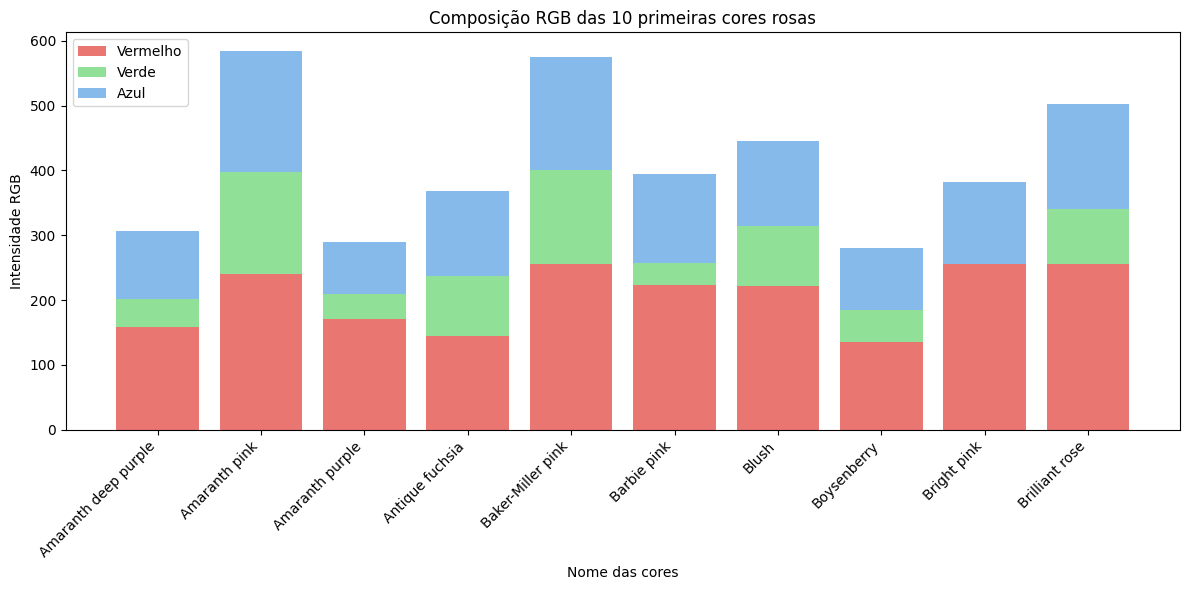

In [47]:
#Atividade 2


import pandas as pd
import matplotlib.pyplot as plt

# Etapa 1 - Importar a base limpa
df = pd.read_csv(
    os.path.join(path, "cores_rosa_limpo.csv")
)

# Selecionar as 10 primeiras cores
dados = df.head(10)

# Etapa 2 e 3 - Criar e personalizar o gráfico
plt.figure(figsize=(12, 6))

plt.bar(dados["Name"], dados["Red (8 bit)"],
        color="#EA7671", label="Vermelho")

plt.bar(dados["Name"], dados["Green (8 bit)"],
        color="#90E098", label="Verde",
        bottom=dados["Red (8 bit)"])

plt.bar(dados["Name"], dados["Blue (8 bit)"],
        color="#85BAEA", label="Azul",
        bottom=dados["Red (8 bit)"] + dados["Green (8 bit)"])

plt.title("Composição RGB das 10 primeiras cores rosas")
plt.xlabel("Nome das cores")
plt.ylabel("Intensidade RGB")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()

plt.show()

